# The Wild Coast seafloor: no seamounts nearby, so what is there instead?

**Linda Angulo Lopez, 22 November 2026.** ODP Academy, *Working with Ocean Data on ODP*, Module 2: GIS.

The Wild Coast runs along South Africa's Eastern Cape, from the Great Kei River mouth to the Mtamvuna River mouth. I downloaded the global seamount layer from the Ocean Data Platform (ODP) for Module 2, and found no seamount within 100 km of this coast.

**Question.** The Wild Coast has no seamounts nearby. What does its seafloor have instead, and how does it compare with the rest of South Africa's coast?

**Working hypothesis**, to test, not to assume: the Wild Coast has one of the narrowest continental shelves in South Africa, and submarine canyons cut close to the shore. Seamounts sit far offshore.

Three measures, for each of four coast reaches (West, South, Wild Coast, KwaZulu-Natal):

1. the distance from the coast to the nearest seamount;
2. the width of the continental shelf;
3. the number of submarine canyons, their density along the coast, and how close they come to the shore.

## Data

All seafloor layers come from the **Seafloor Geomorphic Features Map (GSFM)** on ODP, by GRID-Arendal, CC BY 4.0: Harris, P.T., Macmillan-Lawler, M., Rupp, J., Baker, E.K. (2014), *Geomorphology of the oceans*, Marine Geology 352: 4-24, [doi:10.1016/j.margeo.2014.01.011](https://doi.org/10.1016/j.margeo.2014.01.011).

| Layer | ODP dataset |
| --- | --- |
| Seamounts | [027a6438-2d81-4a6e-91f3-e939e79f7cdd](https://app.hubocean.earth/catalog/dataset/027a6438-2d81-4a6e-91f3-e939e79f7cdd) |
| Canyons | [f9ac8c35-68f8-4c4c-b033-86188608507d](https://app.hubocean.earth/catalog/dataset/f9ac8c35-68f8-4c4c-b033-86188608507d) |
| Shelf | [9dc7ec46-f1db-482f-81aa-c5957296525e](https://app.hubocean.earth/catalog/dataset/9dc7ec46-f1db-482f-81aa-c5957296525e) |
| Slope | [ac8739f5-f616-488e-b23f-e6a715868cba](https://app.hubocean.earth/catalog/dataset/ac8739f5-f616-488e-b23f-e6a715868cba) |

They are open data, read through ODP's OGC API Features with no login or key. The coastline and country outlines come from [Natural Earth](https://www.naturalearthdata.com/) 1:10m (public domain).

The helper functions are in `wild_coast_analysis.py`, next to this notebook. Run it in the `coa` conda environment.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd

import wild_coast_analysis as w

pd.set_option("display.precision", 1)
w.OUTPUTS.mkdir(exist_ok=True)

## 1. Get the data

Each GSFM layer is downloaded once into `data/` (not committed to git) and clipped to the study area, 14-36° E and 40-25° S. ODP's `bbox` filter returned features from outside the box when I tested it, so the clipping is done here.

In [2]:
rsa = w.load_south_africa()
layers = {name: w.load_gsfm(name) for name in ["seamounts", "canyons", "shelf", "slope"]}
{name: len(layer) for name, layer in layers.items()}

{'seamounts': 36, 'canyons': 56, 'shelf': 3, 'slope': 1}

In [3]:
# Everything to the metric CRS (Africa Albers Equal Area) for distances
metric = {name: layer.to_crs(w.CRS_METRIC) for name, layer in layers.items()}
coast = w.load_coastline(rsa)
print(f"Mainland coastline: {coast.length.sum() / 1000:,.0f} km")

Mainland coastline: 3,013 km


## 2. Four coast reaches

I sample the coastline every 10 km and tag each point with its reach, split at:

- **West**: Orange River mouth to Cape Point (18.47° E)
- **South**: Cape Point to the Great Kei River mouth (28.38° E)
- **Wild Coast**: Great Kei River mouth to the Mtamvuna River mouth (31.08° S)
- **KwaZulu-Natal**: Mtamvuna River mouth to Kosi Bay

In [4]:
points = w.coast_points(coast, spacing_m=10_000)
points["reach"].value_counts().reindex(w.REACH_ORDER).rename("points every 10 km")

reach
West              82
South            135
Wild Coast        25
KwaZulu-Natal     60
Name: points every 10 km, dtype: int64

## 3. Distance to the nearest seamount

For each coast point: the distance to the nearest seamount polygon.

In [5]:
points["seamount_km"] = w.nearest_distance_km(points, metric["seamounts"])
points.groupby("reach")["seamount_km"].agg(["min", "median", "max"]).reindex(w.REACH_ORDER)

,min,median,max
reach,,,
West,221.5,439.4,764.2
South,97.1,199.8,269.1
Wild Coast,191.7,303.1,412.5
KwaZulu-Natal,422.5,694.4,942.4


## 4. Shelf width

In the GSFM, the continental slope starts where the shelf ends, at the shelf break. So for each coast point, the distance to the nearest slope polygon is the shelf width there.

In [6]:
points["shelf_width_km"] = w.nearest_distance_km(points, metric["slope"])
points.groupby("reach")["shelf_width_km"].agg(["min", "median", "max"]).reindex(w.REACH_ORDER)

,min,median,max
reach,,,
West,18.6,128.5,195.7
South,20.3,76.3,189.8
Wild Coast,8.2,13.7,19.7
KwaZulu-Natal,2.4,11.8,43.5


## 5. Submarine canyons

Each canyon within 100 km of the coast is given the reach of its nearest coast point. The GSFM sorts canyons into two types: **shelf-incising** canyons cut into the shelf, towards the coast, and **blind** canyons start on the slope.

In [7]:
canyons = w.assign_to_reach(metric["canyons"], points, coast, max_km=100)
coast_km = points.groupby("reach").size() * 10

canyon_table = pd.DataFrame({
    "canyons": canyons.groupby("reach").size(),
    "shelf-incising": canyons[canyons["type"] == "shelf incising"].groupby("reach").size(),
    "closest to shore (km)": canyons.groupby("reach")["coast_km"].min(),
    "median distance to shore (km)": canyons.groupby("reach")["coast_km"].median(),
}).reindex(w.REACH_ORDER).fillna(0)
canyon_table["per 100 km of coast"] = canyon_table["canyons"] / coast_km.reindex(w.REACH_ORDER) * 100
canyon_table

,canyons,shelf-incising,closest to shore (km),median distance to shore (km),per 100 km of coast
reach,,,,,
West,5,2.0,18.8,70.3,0.6
South,17,1.0,30.2,57.0,1.3
Wild Coast,8,2.0,6.4,25.3,3.2
KwaZulu-Natal,7,0.0,16.3,19.1,1.2


## 6. Summary

In [8]:
summary = pd.DataFrame({
    "coast sampled (km)": coast_km,
    "nearest seamount (km)": points.groupby("reach")["seamount_km"].min(),
    "median shelf width (km)": points.groupby("reach")["shelf_width_km"].median(),
    "canyons": canyon_table["canyons"],
    "canyons per 100 km": canyon_table["per 100 km of coast"],
    "closest canyon to shore (km)": canyon_table["closest to shore (km)"],
}).reindex(w.REACH_ORDER)
summary.to_csv(w.OUTPUTS / "wild_coast_summary.csv", float_format="%.1f")
summary

,coast sampled (km),nearest seamount (km),median shelf width (km),canyons,canyons per 100 km,closest canyon to shore (km)
reach,,,,,,
West,820,221.5,128.5,5,0.6,18.8
South,1350,97.1,76.3,17,1.3,30.2
Wild Coast,250,191.7,13.7,8,3.2,6.4
KwaZulu-Natal,600,422.5,11.8,7,1.2,16.3


In [9]:
# Sanity checks
wild = points[points["reach"] == "Wild Coast"]
assert wild["seamount_km"].min() > 100, "a seamount within 100 km of the Wild Coast"
assert points["shelf_width_km"].between(0, 300).all(), "shelf width out of range"
print("Checks passed")

Checks passed


## 7. Maps and chart

Colours: shelf in light blue, canyons in orange (filled for shelf-incising, outline only for blind), seamounts in aqua with a dark outline. The palette was checked for colour-blind separation.

In [10]:
BLUE, ORANGE, AQUA, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
SHELF_FILL, LAND, INK, SURFACE = "#cde2fb", "#e6e4dd", "#0b0b0b", "#fcfcfb"

countries = gpd.read_file(w.DATA / "ne_10m_admin_0_countries.zip").to_crs(w.CRS_METRIC)
canyons_all = metric["canyons"]


def draw_layers(ax, bounds):
    ax.set_facecolor(SURFACE)
    metric["shelf"].plot(ax=ax, color=SHELF_FILL, linewidth=0)
    countries.plot(ax=ax, color=LAND, edgecolor="#b8b6ad", linewidth=0.5)
    blind = canyons_all[canyons_all["type"] == "blind"]
    incising = canyons_all[canyons_all["type"] == "shelf incising"]
    blind.plot(ax=ax, facecolor="none", edgecolor=ORANGE, linewidth=0.8)
    incising.plot(ax=ax, color=ORANGE, edgecolor=ORANGE, linewidth=0.5)
    metric["seamounts"].plot(ax=ax, color=AQUA, edgecolor=INK, linewidth=0.6)
    xmin, ymin, xmax, ymax = bounds
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_color("#d0cec6")


def legend(ax, loc="lower right"):
    from matplotlib.patches import Patch
    handles = [
        Patch(facecolor=SHELF_FILL, label="Continental shelf"),
        Patch(facecolor=ORANGE, label="Canyon, shelf-incising"),
        Patch(facecolor="none", edgecolor=ORANGE, label="Canyon, blind"),
        Patch(facecolor=AQUA, edgecolor=INK, label="Seamount"),
        plt.Line2D([], [], color=BLUE, linewidth=3, label="Wild Coast"),
    ]
    ax.legend(handles=handles, loc=loc, frameon=True, fontsize=8, labelcolor=INK)

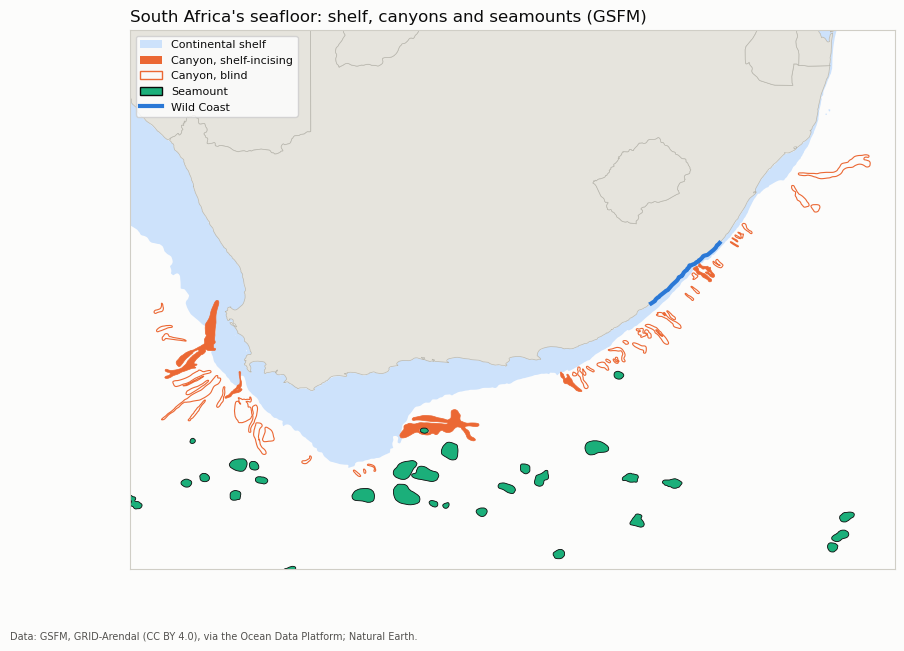

In [11]:
wild_line = gpd.clip(coast, wild.buffer(6_000).union_all())

fig, ax = plt.subplots(figsize=(10, 7), facecolor=SURFACE)
draw_layers(ax, gpd.GeoSeries([w.box(15.5, -39.5, 34.5, -26.0)], crs=4326).to_crs(w.CRS_METRIC).total_bounds)
wild_line.plot(ax=ax, color=BLUE, linewidth=3)
legend(ax, loc="upper left")
ax.set_title("South Africa's seafloor: shelf, canyons and seamounts (GSFM)", loc="left", color=INK, fontsize=12)
fig.text(0.01, 0.01, "Data: GSFM, GRID-Arendal (CC BY 4.0), via the Ocean Data Platform; Natural Earth.", fontsize=7, color="#52514e")
fig.savefig(w.OUTPUTS / "map_overview.png", dpi=150, bbox_inches="tight")
plt.show()

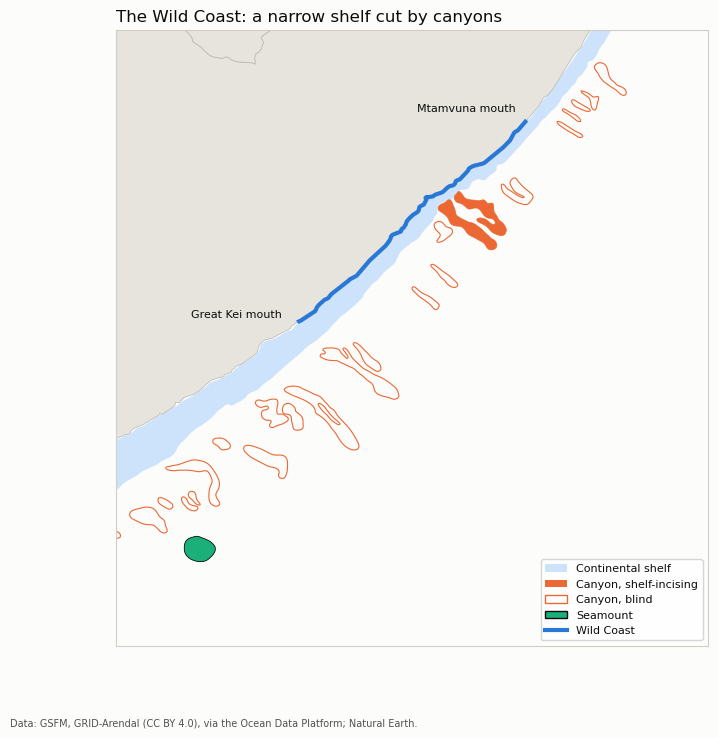

In [12]:
fig, ax = plt.subplots(figsize=(8, 8), facecolor=SURFACE)
draw_layers(ax, gpd.GeoSeries([w.box(27.0, -35.2, 31.6, -30.4)], crs=4326).to_crs(w.CRS_METRIC).total_bounds)
wild_line.plot(ax=ax, color=BLUE, linewidth=3)
for name, (lon, lat) in {"Great Kei mouth": w.KEI_MOUTH, "Mtamvuna mouth": w.MTAMVUNA_MOUTH}.items():
    p = gpd.GeoSeries([w.Point(lon, lat)], crs=4326).to_crs(w.CRS_METRIC).iloc[0]
    ax.annotate(name, (p.x, p.y), xytext=(-8, 6), textcoords="offset points", ha="right", fontsize=8, color=INK)
legend(ax)
ax.set_title("The Wild Coast: a narrow shelf cut by canyons", loc="left", color=INK, fontsize=12)
fig.text(0.01, 0.01, "Data: GSFM, GRID-Arendal (CC BY 4.0), via the Ocean Data Platform; Natural Earth.", fontsize=7, color="#52514e")
fig.savefig(w.OUTPUTS / "map_wild_coast.png", dpi=150, bbox_inches="tight")
plt.show()

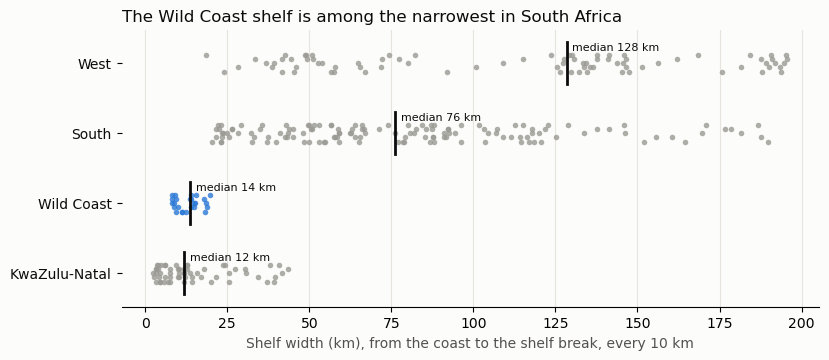

In [13]:
# Shelf width every 10 km, one row per reach; the Wild Coast highlighted
fig, ax = plt.subplots(figsize=(9, 3.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
for i, reach in enumerate(w.REACH_ORDER):
    values = points.loc[points["reach"] == reach, "shelf_width_km"]
    colour = BLUE if reach == "Wild Coast" else GREY
    jitter = (pd.Series(range(len(values))) % 5 - 2) * 0.06
    ax.scatter(values, i + jitter.values, s=16, color=colour, alpha=0.8, linewidths=0)
    median = values.median()
    ax.plot([median, median], [i - 0.3, i + 0.3], color=INK, linewidth=2)
    ax.annotate(f"median {median:.0f} km", (median, i - 0.3), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK, ha="left", va="top")
ax.set_yticks(range(len(w.REACH_ORDER)), w.REACH_ORDER, color=INK)
ax.invert_yaxis()
ax.set_xlabel("Shelf width (km), from the coast to the shelf break, every 10 km", color="#52514e")
ax.grid(axis="x", color="#e6e4dd", linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.set_title("The Wild Coast shelf is among the narrowest in South Africa", loc="left", color=INK, fontsize=12)
fig.savefig(w.OUTPUTS / "chart_shelf_width.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Save the clipped layers

Small GeoJSON files for QGIS, ODP's My Data and the course site, in WGS84.

In [14]:
def save(gdf, name):
    gdf.to_crs(4326).to_file(w.OUTPUTS / f"{name}.geojson", driver="GeoJSON")

save(layers["seamounts"], "sa_seamounts")
save(canyons, "sa_canyons_near_coast")
save(points, "sa_coast_points")
save(layers["shelf"], "sa_shelf")
sorted(p.name for p in w.OUTPUTS.glob("*.geojson"))

['sa_canyons_near_coast.geojson',
 'sa_coast_points.geojson',
 'sa_seamounts.geojson',
 'sa_shelf.geojson']

## 9. What this says, and what it cannot

**Results.** The table in section 6 answers the question. The Wild Coast has no seamount within about 190 km. Its shelf is a narrow strip, a median of about 14 km against about 76 km on the South coast and about 128 km on the West coast; only KwaZulu-Natal is as narrow. Submarine canyons come closer to shore off the Wild Coast than anywhere else in South Africa, under 10 km at the closest, and it has the most canyons per 100 km of coast. So the hypothesis holds: the Wild Coast's deep-sea features are canyons cutting towards the shore, not seamounts.

**Why it may matter.** A narrow shelf brings the Agulhas Current and deep water close to the coast, and canyons can channel deep water and nutrients towards the shelf. Whether that shapes the Wild Coast's marine life, for example in and around the Pondoland Marine Protected Area, is a question this geomorphology alone cannot answer.

**Limits.**

- The GSFM is a global map built from about 1 km bathymetry (SRTM30_PLUS). Small canyons and local detail are missing; the numbers compare reaches, they are not survey results.
- Distances are measured in Africa Albers Equal Area, so they are accurate to within a few percent.
- The reach boundaries are fixed points chosen by me; moving them a few kilometres changes the counts a little.
- This is geomorphology only. Linking it to ecology, such as the Agulhas Current, fisheries or the MPA, needs more data, which is for Module 3 (Code) and Module 4 (Plan).